<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-10/policy-gradient-cartpole.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Policy gradient on the cart-pole

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

### Learning the policy directly

Q-learning learns values and derives the policy from them, by taking the action with the largest value. This works well with a few discrete actions. It becomes awkward when the actions are continuous, such as a throttle or a joint torque, because the maximum over actions is then an optimisation problem of its own at every step, and a small change of the values can flip the greedy action abruptly. Policy-gradient methods parametrise the policy itself, $\pi_\theta(a\mid s)$, as a neural network that outputs a probability distribution over actions, and adjust $\theta$ by gradient ascent on the expected return. The policy changes smoothly with $\theta$, and continuous actions only need a continuous output distribution.

### The difficulty

The expected return depends on $\theta$ through the trajectories that the policy produces, and these pass through the environment, whose dynamics we do not know and cannot differentiate. The log-derivative trick writes the gradient of the expected return as an average over trajectories of quantities that involve only the policy network, so it can be estimated from played episodes. Such estimates are noisy, and the reward-to-go and the baseline reduce the noise.

### REINFORCE on the cart-pole

We introduce the cart-pole, derive the policy gradient and implement the REINFORCE algorithm of Williams [R. J. Williams, Mach. Learn. **8**, 229 (1992), [doi:10.1007/BF00992696](https://doi.org/10.1007/BF00992696)]. We compute the exact mean and variance of the gradient estimate in a problem with one state and two actions, with and without a baseline. We then compare REINFORCE with and without a learned baseline on the cart-pole over several seeds and watch the policy in videos.

All random generators are seeded, so every run gives the same numbers.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*.
> 2. Gymnasium is installed with `!pip install gymnasium`. PyTorch, `imageio` and `matplotlib` are pre-installed.
> 3. The notebook runs on the CPU in about ten minutes, most of it in the training. Run the cells in order.

In [1]:
# Imports, colours and the helpers that play an episode and write a video. They only simulate and record.
import os, json, time
os.environ["CUDA_VISIBLE_DEVICES"] = ""          # CPU only
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import gymnasium as gym
import imageio
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Video, display

plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13,
                     "ytick.labelsize": 13, "legend.fontsize": 13, "figure.titlesize": 17})
UJNavy, UJBlue, UJSky, DSOrange, UJGray = "#002B5C", "#005CA7", "#3E8FD0", "#D35A05", "#5A6270"
for d in ("figures", "results", "videos"): os.makedirs(d, exist_ok=True)
torch.set_num_threads(2)
NUMBERS = {}                                     # numbers quoted in the text, written to a file at the end

def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

def run_episode(policy, seed, record=False, max_steps=500):
    # play one episode with policy(state) -> action, return the number of steps and, if asked, the rendered frames
    e = gym.make("CartPole-v1", render_mode="rgb_array" if record else None)
    s, _ = e.reset(seed=seed); frames, T = [], 0
    for T in range(1, max_steps + 1):
        if record: frames.append(e.render())
        s, r, terminated, truncated, _ = e.step(policy(s))
        if terminated or truncated: break
    if record: frames.append(e.render())
    e.close()
    return T, frames

def text_image(width, height, text, size, xy, anchor):
    img = Image.new("RGB", (width, height), (255, 255, 255))
    ImageDraw.Draw(img).text(xy, text, fill=(0, 43, 92), anchor=anchor, font=ImageFont.load_default(size=size))
    return np.asarray(img)

def save_video(policy, seeds, name, min_seconds=16, fps=25):
    # Episodes with the given seeds, one after another until the video lasts min_seconds, one frame per step.
    # A band above the picture shows episode and step, and a white card announces the next episode.
    video = []
    for k, seed in enumerate(seeds, start=1):
        if k > 1: video += [text_image(video[-1].shape[1], video[-1].shape[0], f"episode {k}", 40, (video[-1].shape[1] // 2, video[-1].shape[0] // 2), "mm")] * (fps // 2)
        T, frames = run_episode(policy, seed=seed, record=True)
        band = lambda f, txt: np.vstack([text_image(f.shape[1], 28, txt, 18, (8, 4), "la"), f])
        video += [band(f, f"episode {k}    step {t}") for t, f in enumerate(frames)]
        video += [band(frames[-1], f"episode {k} ended after {len(frames) - 1} steps, return {T:.0f}")] * (fps // 2)
        if len(video) >= min_seconds * fps: break
    imageio.mimsave(f"videos/{name}.mp4", video, fps=fps, macro_block_size=8)
    os.makedirs(f"figures/frames_{name}", exist_ok=True)
    imageio.imwrite(f"figures/frames_{name}/0.png", video[0][::2, ::2])          # still picture of the first frame
    print(f"{name}: {k} episodes, {len(video) / fps:.1f} s")

## The cart-pole

A pole is hinged on a cart that moves along a track without friction. The agent pushes the cart left or right with a fixed force at every time step of $0.02\,$s and has to keep the pole upright. The problem goes back to Barto, Sutton and Anderson [A. G. Barto, R. S. Sutton, C. W. Anderson, IEEE Trans. Syst. Man Cybern. **SMC-13**, 834 (1983), [doi:10.1109/TSMC.1983.6313077](https://doi.org/10.1109/TSMC.1983.6313077)], and we use its Gymnasium implementation `CartPole-v1`.

| Object | In the cart-pole |
|---|---|
| state $s$ | four numbers, the cart position $x$, its velocity $\dot x$, the pole angle $\varphi$ from the vertical and its angular velocity $\dot\varphi$ |
| action $a$ | push the cart to the left or to the right |
| reward $r$ | $+1$ for every step in which the pole is still up |
| episode | ends when $|\varphi|>12^\circ$, when the cart leaves the track $|x|>2.4$, or after 500 steps |

The return of an episode is the number of steps the pole stayed up, at most 500. The upright pole is an unstable equilibrium, an inverted pendulum, so a policy that does nothing loses the pole within a few dozen steps.

In [2]:
rng = np.random.default_rng(0)
T_rand, _ = run_episode(lambda s: int(rng.integers(2)), seed=1)
lengths_random = [run_episode(lambda s: int(rng.integers(2)), seed=100 + k)[0] for k in range(100)]
print(f"random pushes: {T_rand} steps in one episode, mean episode length {np.mean(lengths_random):.1f} steps over 100 episodes")
NUMBERS["randMean"] = round(float(np.mean(lengths_random)), 1)

random pushes: 20 steps in one episode, mean episode length 23.0 steps over 100 episodes


Random pushes keep the pole up for about twenty steps, less than half a second of simulated time.

*Exercise.* Try the hand-made rule "push in the direction in which the pole leans" and measure its mean episode length.

## The policy gradient

### Objective

A trajectory $\tau=(s_0,a_0,r_1,s_1,a_1,\dots,s_T)$ occurs with the probability

$$ p_\theta(\tau)=p(s_0)\prod_{t=0}^{T-1}\pi_\theta(a_t\mid s_t)\,p(s_{t+1}\mid s_t,a_t), \tag{1}$$

a product of the initial distribution, the choices of the policy and the answers of the environment. We maximise the expected return

$$ J(\theta)=\mathbb E_{\tau\sim p_\theta}\big[G(\tau)\big]=\sum_\tau p_\theta(\tau)\,G(\tau),\qquad G(\tau)=\sum_{t=0}^{T-1}\gamma^t r_{t+1}. \tag{2}$$

### Log-derivative trick

The parameters enter only through the probabilities $p_\theta(\tau)$. Using $\nabla_\theta p_\theta=p_\theta\nabla_\theta\ln p_\theta$,

$$ \nabla_\theta J=\sum_\tau p_\theta(\tau)\,\nabla_\theta\ln p_\theta(\tau)\,G(\tau)=\mathbb E_{\tau\sim p_\theta}\big[\nabla_\theta\ln p_\theta(\tau)\,G(\tau)\big]. \tag{3}$$

The gradient of an average became the average of a product, which can be estimated from sampled trajectories. The logarithm of equation (1) is a sum, and the terms $\ln p(s_0)$ and $\ln p(s_{t+1}\mid s_t,a_t)$ do not depend on $\theta$, so their gradients vanish,

$$ \nabla_\theta\ln p_\theta(\tau)=\sum_{t=0}^{T-1}\nabla_\theta\ln\pi_\theta(a_t\mid s_t). \tag{4}$$

The unknown dynamics drop out. Only the gradient of the policy network is needed, which backpropagation provides.

### Reward-to-go

The score $\nabla_\theta\ln\pi_\theta(a\mid s)$ has zero mean under the policy, since the probabilities sum to one,

$$ \mathbb E_{a\sim\pi_\theta}\big[\nabla_\theta\ln\pi_\theta(a\mid s)\big]=\sum_a\nabla_\theta\pi_\theta(a\mid s)=\nabla_\theta\sum_a\pi_\theta(a\mid s)=\nabla_\theta1=0. \tag{5}$$

Inserting equation (4) into equation (3) multiplies every score $\nabla_\theta\ln\pi_\theta(a_t\mid s_t)$ with the whole return, including the rewards collected before time $t$. Such a past reward $r_{k+1}$ with $k<t$ drops out of the average. Once the trajectory up to $s_t$ is fixed, $r_{k+1}$ is a fixed number, and the remaining average of the score over $a_t\sim\pi_\theta(\cdot\mid s_t)$ vanishes by equation (5), so $\mathbb E[r_{k+1}\nabla_\theta\ln\pi_\theta(a_t\mid s_t)]=0$. The rewards from time $t$ on add up to $\gamma^t G_t$, and the exact policy gradient is

$$ \nabla_\theta J=\mathbb E\Big[\sum_{t=0}^{T-1}\gamma^t\,\nabla_\theta\ln\pi_\theta(a_t\mid s_t)\,G_t\Big],\qquad G_t=\sum_{k=t}^{T-1}\gamma^{k-t}r_{k+1}. \tag{6}$$

$G_t$ is the reward-to-go, the return from time $t$ on. The estimator used in practice, and in our training, drops the factor $\gamma^t$,

$$ \hat g=\mathbb E\Big[\sum_{t=0}^{T-1}\nabla_\theta\ln\pi_\theta(a_t\mid s_t)\,G_t\Big]\approx\nabla_\theta J. \tag{7}$$

The objective $J$ counts a decision at time $t$ with the weight $\gamma^t$, while $\hat g$ treats every visited state as a start state. With $\gamma=0.99$ and episodes of hundreds of steps the exact weights would make late decisions almost irrelevant, which is why most implementations use $\hat g$, although $\hat g$ need not be the gradient of any function of $\theta$ [C. Nota and P. S. Thomas, AAMAS (2020), [arXiv:1906.07073](https://arxiv.org/abs/1906.07073)]. The log-probability of every action taken is changed in proportion to the return that followed it. On the cart-pole every reward is $+1$, so $G_t$ is positive and every sampled action has its log-probability pushed up, most strongly for actions followed by a long survival of the pole.

### Baseline

By equation (5), any function $b(s_t)$ of the state, the baseline, can be subtracted from $G_t$ without changing the mean of the estimate (7). A baseline close to the typical return can reduce its variance considerably. A common choice is the value $b(s_t)=V(s_t)$, learned by a second network. The difference $G_t-V(s_t)$ says whether the action did better or worse than usual in this state, and only this difference pushes the policy.

### Algorithm

REINFORCE plays $N$ episodes with the current policy, computes $G_t$ for every step and takes a gradient step on the loss

$$ L(\theta)=-\frac1{N}\sum_{\text{steps}}\ln\pi_\theta(a_t\mid s_t)\,\big(G_t-b(s_t)\big), \tag{8}$$

where the sum runs over all steps of the $N$ episodes and the division by the number of episodes $N$ turns the sum into an average over episodes. The gradient of $L$ is minus the sampled estimate of $\hat g$. With a learned baseline the value network $V_w$ is trained at the same time by regression of $V_w(s_t)$ on $G_t$.

In [3]:
GAMMA = 0.99                                       # discount factor

class Policy(nn.Module):
    # pi_theta(a|s): four state numbers in, a probability for each of the two actions out (softmax of the logits)
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 2))
    def dist(self, s):
        return torch.distributions.Categorical(logits=self.net(s))

def make_value():
    # V_w(s): the baseline network
    return nn.Sequential(nn.Linear(4, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 1))

def play(policy, env, seed=None):
    # one episode with actions sampled from the policy; returns states, actions, rewards as tensors
    S, A, R = [], [], []
    s, _ = env.reset(seed=seed)
    while True:
        st = torch.as_tensor(s, dtype=torch.float32)
        with torch.no_grad(): a = int(policy.dist(st).sample())
        s, r, terminated, truncated, _ = env.step(a)
        S.append(st); A.append(a); R.append(r)
        if terminated or truncated: break
    return torch.stack(S), torch.as_tensor(A), torch.as_tensor(R, dtype=torch.float32)

def rewards_to_go(R, gamma):
    G = torch.zeros_like(R); g = 0.0
    for t in reversed(range(len(R))):           # G_t = r_{t+1} + gamma G_{t+1}, from the end of the episode
        g = R[t] + gamma * g; G[t] = g
    return G

## Baseline in a two-action example

The effect of a baseline can be computed exactly in the smallest possible problem. There is one state and two actions $a_1$ and $a_2$ with deterministic rewards $R(a_1)=2$ and $R(a_2)=1$. The policy has one parameter $\theta$ and chooses $a_1$ with the probability $\pi_\theta(a_1)=\sigma(\theta)=p$, where $\sigma$ is the logistic function, and $a_2$ with the probability $1-p$. The expected return and its exact gradient are

$$ J(\theta)=2p+(1-p),\qquad \frac{dJ}{d\theta}=p(1-p), \tag{9}$$

because $d\sigma/d\theta=\sigma(1-\sigma)$. The scores of the two actions are $\partial_\theta\ln\pi_\theta(a_1)=1-p$ and $\partial_\theta\ln\pi_\theta(a_2)=-p$. REINFORCE draws one action $a$ from the policy and uses the single-sample estimate

$$ g=\big(R(a)-b\big)\,\partial_\theta\ln\pi_\theta(a), \tag{10}$$

with a constant baseline $b$. Averaged over the two actions, the mean of $g$ is $p(1-p)$ for every $b$, in agreement with equation (5). The variance of $g$ depends on $b$. We evaluate the mean and the variance at $\theta=0$, where $p=1/2$ and the exact gradient is $0.25$, for no baseline, for the mean reward $b=1.5$ under the policy, and for the badly chosen $b=10$.

exact gradient p(1-p) = 0.25
b =  0.0:  g =  1.00 (a_1) or -0.50 (a_2),  mean 0.2500,  variance 0.5625
b =  1.5:  g =  0.25 (a_1) or  0.25 (a_2),  mean 0.2500,  variance 0.0000
b = 10.0:  g = -4.00 (a_1) or  4.50 (a_2),  mean 0.2500,  variance 18.0625


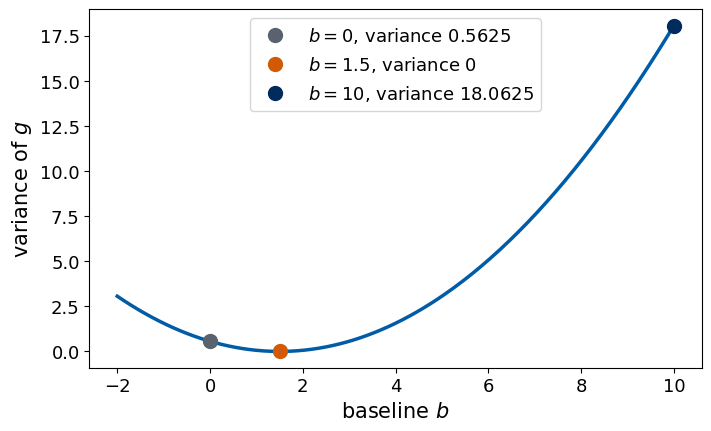

In [4]:
R = np.array([2.0, 1.0])                          # rewards of a_1 and a_2
p = 0.5                                           # pi(a_1) = sigma(0)
prob = np.array([p, 1 - p])                       # probabilities of a_1 and a_2
score = np.array([1 - p, -p])                     # d ln pi(a) / d theta for a_1 and a_2

def estimator_stats(b):
    g = (R - b) * score                           # the two possible values of the estimate, equation (10)
    mean = np.sum(prob * g)
    return g, mean, np.sum(prob * g**2) - mean**2

print(f"exact gradient p(1-p) = {p * (1 - p)}")
for b, var_expected in ((0.0, 0.5625), (1.5, 0.0), (10.0, 18.0625)):
    g, mean, var = estimator_stats(b)
    print(f"b = {b:4.1f}:  g = {g[0]:5.2f} (a_1) or {g[1]:5.2f} (a_2),  mean {mean:.4f},  variance {var:.4f}")
    assert np.isclose(mean, 0.25) and np.isclose(var, var_expected)

bs = np.linspace(-2, 10, 241)
fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
ax.plot(bs, [estimator_stats(b)[2] for b in bs], color=UJBlue, lw=2.5)
for b, col in ((0.0, UJGray), (1.5, DSOrange), (10.0, UJNavy)):
    v = estimator_stats(b)[2]
    ax.plot(b, v, "o", ms=10, color=col, label=f"$b={b:g}$, variance {v:g}")
ax.set_xlabel("baseline $b$"); ax.set_ylabel("variance of $g$")
ax.legend(loc="upper center")
save(fig, "fig_toy_baseline"); plt.show()

Both rewards are positive, so without a baseline either sampled action has its log-probability pushed up, $a_1$ more strongly than $a_2$, and only the difference of the two pushes, averaged over many samples, favours the better action. The single estimate then jumps between $1$ and $-0.5$. With the baseline $b=1.5$, the mean reward under the policy, the weight $R(a)-b$ is positive for the better action and negative for the worse one, and both actions give the same estimate $0.25$, so the variance vanishes. The baseline $b=10$ makes both weights strongly negative, the estimate jumps between $-4$ and $4.5$ and its variance grows to $18.0625$. All three estimates have the same mean $0.25$, equal to the exact gradient. A baseline never changes the mean of the estimate, and a baseline close to the average return reduces the variance. The learned value $V_w(s_t)$ on the cart-pole plays the role of $b=1.5$, estimated separately for every state.

## Training

We train both variants, REINFORCE with the reward-to-go and REINFORCE with a learned baseline, for 600 episodes each, one gradient step of the policy after every batch of five episodes, with five random seeds per variant. Both use the Adam optimiser with learning rate $10^{-3}$. The value network makes 20 regression steps on every batch, so that the baseline follows the improving policy. We store the policy network at several moments of the first seed with a baseline to watch it later. The weight $G_t-V_w(s_t)$ uses the value network before it is fitted to the batch, so that the baseline does not depend on the sampled return from which it is subtracted.

In [5]:
N_EPISODES, BATCH, LR_PI, LR_V, V_STEPS = 600, 5, 1e-3, 1e-3, 20
SNAP_EPISODES = (0, 100, 200, 600)

def train(use_baseline, seed):
    torch.manual_seed(seed); env = gym.make("CartPole-v1")
    pol, val = Policy(), make_value()
    opt, vopt = torch.optim.Adam(pol.parameters(), lr=LR_PI), torch.optim.Adam(val.parameters(), lr=LR_V)
    lengths, snaps = [], {0: {k: v.clone() for k, v in pol.state_dict().items()}}
    for b in range(N_EPISODES // BATCH):
        batch = [play(pol, env, seed=seed * 100_000 + b * BATCH + k) for k in range(BATCH)]
        S = torch.cat([x[0] for x in batch]); A = torch.cat([x[1] for x in batch])
        G = torch.cat([rewards_to_go(x[2], GAMMA) for x in batch])
        if use_baseline:
            adv = G - val(S).squeeze(-1).detach()             # weight G_t - V(s_t), with the value before this batch
            for _ in range(V_STEPS):                           # regression of V_w(s_t) on G_t
                vloss = ((val(S).squeeze(-1) - G)**2).mean(); vopt.zero_grad(); vloss.backward(); vopt.step()
        else:
            adv = G                                            # weight G_t
        loss = -(pol.dist(S).log_prob(A) * adv).sum() / BATCH  # equation (8)
        opt.zero_grad(); loss.backward(); opt.step()
        lengths += [len(x[2]) for x in batch]
        if len(lengths) in SNAP_EPISODES: snaps[len(lengths)] = {k: v.clone() for k, v in pol.state_dict().items()}
    return np.array(lengths), snaps

NUMBERS["policyParams"] = sum(q.numel() for q in Policy().parameters())
NUMBERS["valueParams"] = sum(q.numel() for q in make_value().parameters())
t0 = time.time(); runs = {}
for use_b in (False, True):
    for seed in range(5):
        runs[(use_b, seed)] = train(use_b, seed)
        print(f"baseline={use_b!s:5s} seed {seed}: mean length of the last 50 episodes {runs[(use_b, seed)][0][-50:].mean():6.1f}")
print(f"training time {time.time() - t0:.0f} s")
torch.save(runs[(True, 0)][1], "results/cp_snapshots.pt")   # the stored policies, for the videos

baseline=False seed 0: mean length of the last 50 episodes  329.4


baseline=False seed 1: mean length of the last 50 episodes  259.1


baseline=False seed 2: mean length of the last 50 episodes  267.0


baseline=False seed 3: mean length of the last 50 episodes  403.3


baseline=False seed 4: mean length of the last 50 episodes  307.5


baseline=True  seed 0: mean length of the last 50 episodes  489.8


baseline=True  seed 1: mean length of the last 50 episodes  474.6


baseline=True  seed 2: mean length of the last 50 episodes  463.9


baseline=True  seed 3: mean length of the last 50 episodes  492.3


baseline=True  seed 4: mean length of the last 50 episodes  384.8
training time 849 s


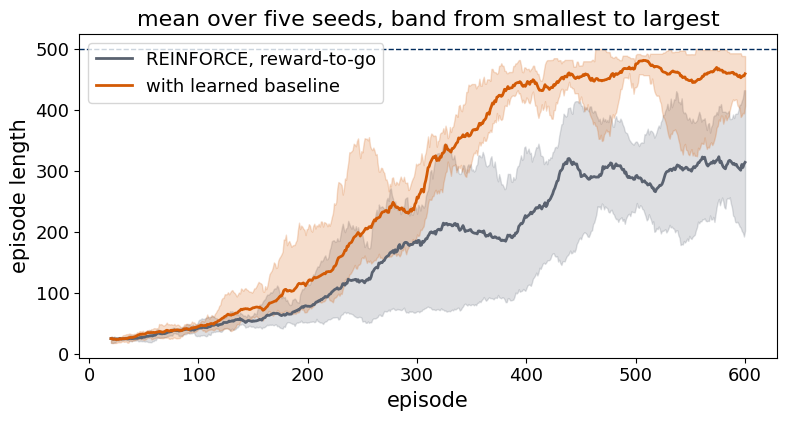

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2)); w = 20
for use_b, col, lab in ((False, UJGray, "REINFORCE, reward-to-go"), (True, DSOrange, "with learned baseline")):
    L = np.array([runs[(use_b, s)][0] for s in range(5)])
    sm = np.array([np.convolve(l, np.ones(w) / w, "valid") for l in L])
    x = np.arange(w, N_EPISODES + 1)
    ax.plot(x, sm.mean(0), color=col, lw=2, label=lab)
    ax.fill_between(x, sm.min(0), sm.max(0), color=col, alpha=0.2)
    NUMBERS["last" + ("Base" if use_b else "Plain")] = round(float(L[:, -50:].mean()), 1)
    NUMBERS["early" + ("Base" if use_b else "Plain")] = round(float(L[:, 100:200].mean()), 1)   # episodes 101-200
ax.axhline(500, color=UJNavy, ls="--", lw=1)
ax.set_xlabel("episode"); ax.set_ylabel("episode length"); ax.legend(loc="upper left")
ax.set_title("mean over five seeds, band from smallest to largest")
save(fig, "fig_cp_learning"); plt.show()

Both variants learn to balance the pole, and the band shows how much the seeds differ. With the baseline the episodes become long sooner, the final lengths are higher, and the seeds differ less. The learned baseline acts as $b=1.5$ did in the two-action example, and a less noisy gradient allows steadier progress with the same number of episodes. Policy-gradient learning remains noisy, and a run can reach 500 steps and drop again when an unlucky batch pushes the policy too far. Actor-critic methods go one step further and use the learned value, the critic, both as the baseline and in place of the later rewards in $G_t$, as in temporal-difference learning.

## Watching the policy learn

We replay the greedy policy, which takes the more probable action, stored after 0, 100, 200 and 600 training episodes of the first seed with a baseline, in one fixed test episode.

In [7]:
greedy = lambda pol: (lambda s: int(pol.net(torch.as_tensor(s, dtype=torch.float32)).argmax()))
snaps = runs[(True, 0)][1]
for k, ep in enumerate(SNAP_EPISODES):
    pol = Policy(); pol.load_state_dict(snaps[ep])
    T, _ = run_episode(greedy(pol), seed=3)
    NUMBERS["snap" + "ABCD"[k]] = T                     # letters: LaTeX macro names cannot contain digits
    print(f"policy after {ep:4d} training episodes: pole up for {T} steps")

policy after    0 training episodes: pole up for 9 steps
policy after  100 training episodes: pole up for 81 steps
policy after  200 training episodes: pole up for 446 steps
policy after  600 training episodes: pole up for 500 steps


The untrained network loses the pole within a few steps. With training the agent learns to react to the tilt, the episodes become much longer, and the final policy keeps the pole up for the whole episode of 500 steps with small corrections. Three videos, each made of several episodes played one after another, show random pushes, the policy after 100 training episodes and the trained policy.

In [8]:
rng_v = np.random.default_rng(5)
save_video(lambda s: int(rng_v.integers(2)), range(200, 300), "cp_random", min_seconds=30, fps=10)   # short episodes, one fifth of real speed
pol_poor, pol_good = Policy(), Policy()
pol_poor.load_state_dict(snaps[100]); pol_good.load_state_dict(snaps[600])
save_video(greedy(pol_poor), range(200, 300), "cp_poor")                                        # half of real speed
save_video(greedy(pol_good), range(200, 300), "cp_trained")
for name in ("cp_random", "cp_poor", "cp_trained"): display(Video(f"videos/{name}.mp4", embed=True, width=420))

cp_random: 10 episodes, 30.3 s


cp_poor: 4 episodes, 16.1 s


cp_trained: 1 episodes, 20.5 s


*Exercise.* Train with `BATCH = 1` and with `BATCH = 20` and compare the learning curves and the training times.

In [9]:
# Write the numbers quoted in the text to files used for typesetting (LaTeX macros such as \pglastBase).
with open("results/numbers_pg.json", "w") as f: json.dump(NUMBERS, f, indent=1)
with open("results/nb_numbers_pg.tex", "w") as f:
    for k, v in NUMBERS.items(): f.write(f"\\newcommand{{\\pg{k}}}{{{v}}}\n")
print(NUMBERS)

{'randMean': 23.0, 'policyParams': 4610, 'valueParams': 4545, 'lastPlain': 313.3, 'earlyPlain': 61.3, 'lastBase': 461.1, 'earlyBase': 85.2, 'snapA': 9, 'snapB': 81, 'snapC': 446, 'snapD': 500}
